In [1]:
# ── 0. Imports & Setup ────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats import gaussian_kde

# Consistent style across all charts
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.linestyle': '--',
    'grid.alpha': 0.4,
    'font.family': 'sans-serif',
})

PALETTE = '#2563EB'   # primary blue
ACCENT  = '#DC2626'   # accent red (used for overlays)

print('Libraries loaded.')

Libraries loaded.


In [2]:
# ── 1. Load Data ──────────────────────────────────────────────────────────────
DATA_PATH = 'output_data/transactions.csv'
SAMPLE_N  = 200_000

df = pd.read_csv(
    DATA_PATH,
    sep='|',
    nrows=SAMPLE_N,
    usecols=['unix_time', 'transaction_velocity', 'amt', 'mcc', 'lat', 'long', 'category'],
)

print(f'Loaded {len(df):,} rows.')
print(df.dtypes)
df.head()

Loaded 200,000 rows.
lat                     float64
long                    float64
unix_time                 int64
category                 object
amt                     float64
mcc                       int64
transaction_velocity      int64
dtype: object


,lat,long,unix_time,category,amt,mcc,transaction_velocity
0,37.1989,-76.5821,1767345928,food_dining,93.00,5812,0
1,37.1989,-76.5821,1767751202,food_dining,62.38,5812,0
2,37.1989,-76.5821,1767783881,food_dining,41.87,5812,1
3,37.1989,-76.5821,1768147920,food_dining,90.64,5812,0
4,37.1989,-76.5821,1768237814,food_dining,7.35,5812,0


---
## Chart 1 — `unix_time`: Transactions Per Day (Time-Series Line Chart)

**Why this chart?**  
`unix_time` is a continuous integer timestamp. Aggregating by **calendar day** (x-axis) and plotting **transaction count** (y-axis) reveals temporal patterns — peaks on weekends, holidays, or seasonal spikes — which are a key signal for anomaly and fraud detection models.

**Axis rationale:**
- **x-axis** = date (derived from `unix_time`): natural temporal ordering  
- **y-axis** = transaction count per day: measures volume variance over time

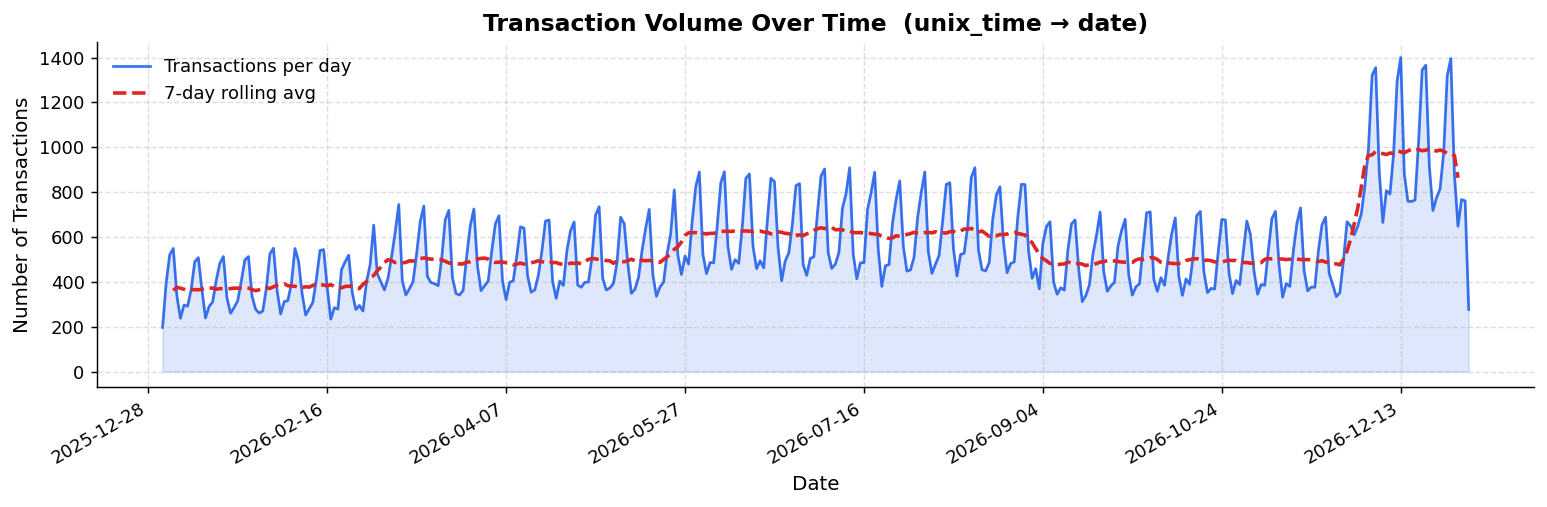

In [3]:
# ── Chart 1: unix_time → Time-Series Line Chart ───────────────────────────────

# Convert unix_time (seconds since epoch) to a date
df['date'] = pd.to_datetime(df['unix_time'], unit='s').dt.normalize()

daily_counts = df.groupby('date').size().reset_index(name='tx_count')

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    daily_counts['date'],
    daily_counts['tx_count'],
    color=PALETTE,
    linewidth=1.5,
    alpha=0.9,
    label='Transactions per day',
)
ax.fill_between(
    daily_counts['date'],
    daily_counts['tx_count'],
    alpha=0.15,
    color=PALETTE,
)

# Rolling 7-day average
rolling_avg = daily_counts['tx_count'].rolling(7, center=True).mean()
ax.plot(
    daily_counts['date'],
    rolling_avg,
    color=ACCENT,
    linewidth=2,
    linestyle='--',
    label='7-day rolling avg',
)

ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('Number of Transactions', fontsize=11)
ax.set_title('Transaction Volume Over Time  (unix_time → date)', fontsize=13, fontweight='bold')
ax.legend(frameon=False)
ax.xaxis.set_major_locator(mticker.MaxNLocator(10))
fig.autofmt_xdate(rotation=30)

plt.tight_layout()
plt.show()

---
## Chart 2 — `transaction_velocity`: Distribution Bar Chart

**Why this chart?**  
`transaction_velocity` is a discrete integer (observed range 0–16) representing how many transactions occurred in a short time window for a given card. It is designed to flag rapid, automated fraud patterns (e.g., card testing). A **bar chart** directly maps each velocity value to its frequency, making the long tail at high velocities immediately visible.

**Axis rationale:**
- **x-axis** = velocity value (discrete integer): the feature itself  
- **y-axis** = transaction count: how often each velocity level occurs, revealing distributional variance

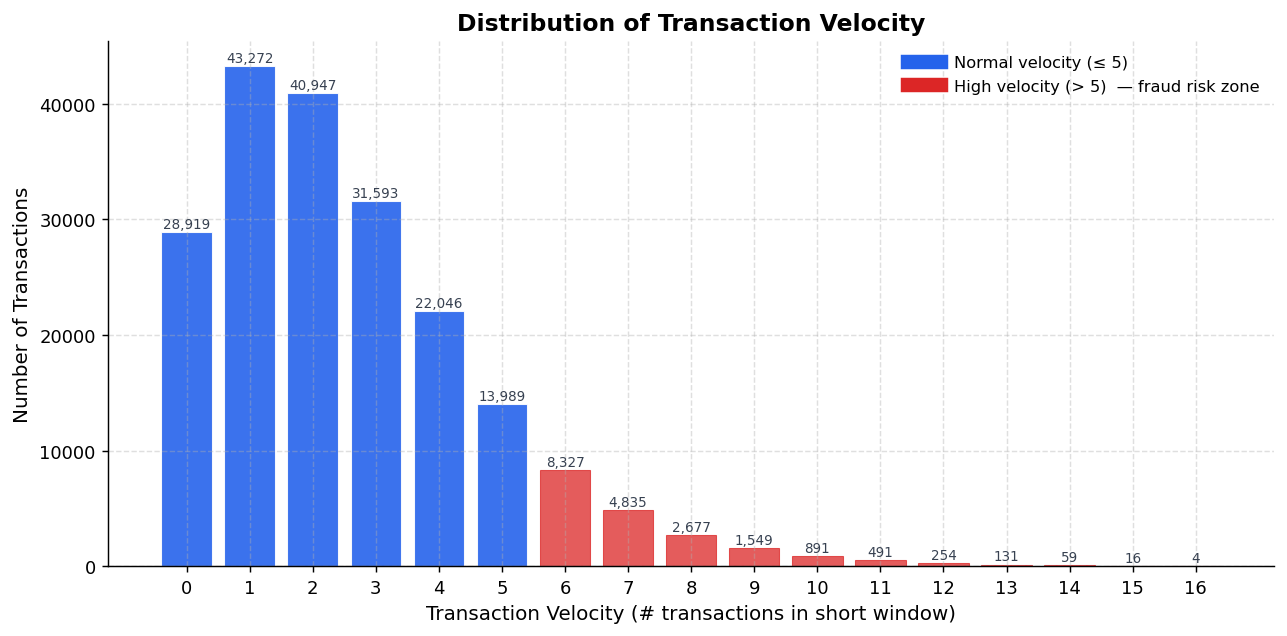

In [4]:
# ── Chart 2: transaction_velocity → Bar Chart ─────────────────────────────────

vel_counts = (
    df['transaction_velocity']
    .value_counts()
    .sort_index()
    .reset_index()
)
vel_counts.columns = ['velocity', 'count']

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    vel_counts['velocity'],
    vel_counts['count'],
    color=PALETTE,
    edgecolor='white',
    linewidth=0.6,
    alpha=0.9,
)

# Annotate bar heights
for bar in bars:
    h = bar.get_height()
    if h > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 100,
            f'{int(h):,}',
            ha='center',
            va='bottom',
            fontsize=7.5,
            color='#374151',
        )

# Highlight the long tail (velocity > 5) as potential fraud zone
threshold = 5
for bar, vel in zip(bars, vel_counts['velocity']):
    if vel > threshold:
        bar.set_color(ACCENT)
        bar.set_alpha(0.75)

legend_elements = [
    Line2D([0], [0], color=PALETTE, linewidth=8, label='Normal velocity (≤ 5)'),
    Line2D([0], [0], color=ACCENT,  linewidth=8, label='High velocity (> 5)  — fraud risk zone'),
]
ax.legend(handles=legend_elements, frameon=False, fontsize=9)

ax.set_xlabel('Transaction Velocity (# transactions in short window)', fontsize=11)
ax.set_ylabel('Number of Transactions', fontsize=11)
ax.set_title('Distribution of Transaction Velocity', fontsize=13, fontweight='bold')
ax.set_xticks(vel_counts['velocity'])

plt.tight_layout()
plt.show()

---
## Chart 3 — `amt`: Histogram + KDE (Transaction Amount Distribution)

**Why this chart?**  
`amt` is a continuous decimal in the range \$1–\$500. The distribution is **right-skewed** — most transactions are small, but a long tail of large amounts exists. A **histogram with a KDE overlay** captures both the bin-level frequency and the smooth probability density in one view.

**Axis rationale:**
- **x-axis** = transaction amount (\$): the variable whose spread we measure  
- **y-axis** = density (KDE) / count: how often each amount range appears — reveals skewness and variance of spending patterns

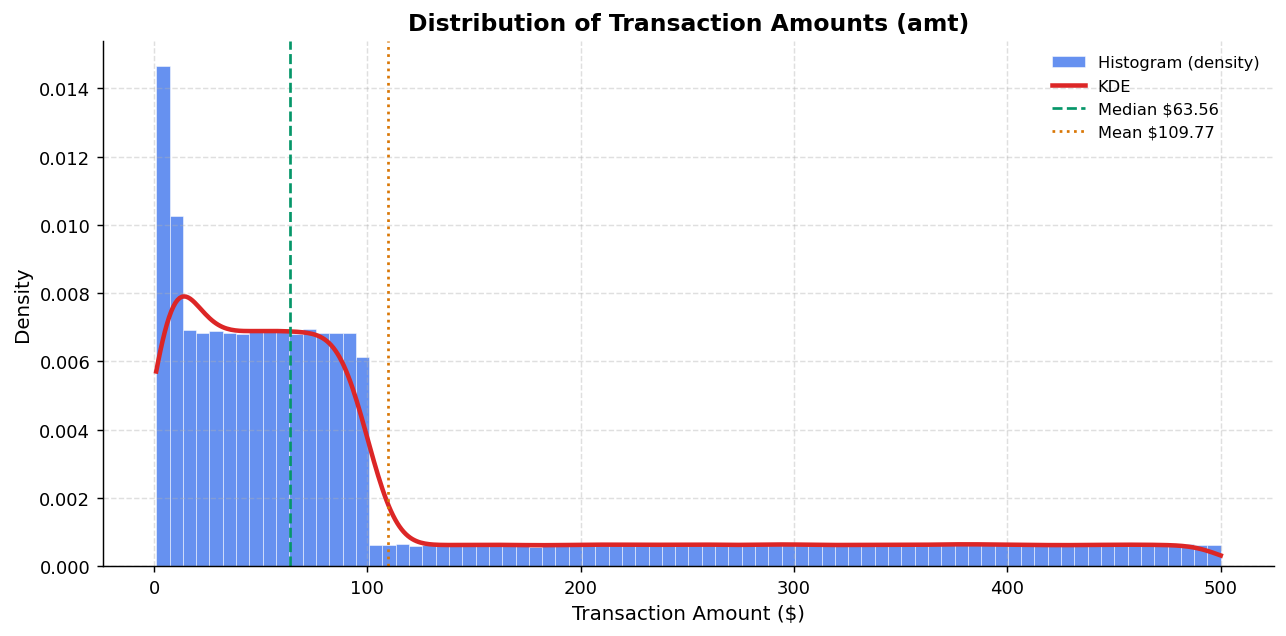

In [5]:
# ── Chart 3: amt → Histogram + KDE ───────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    df['amt'],
    bins=80,
    color=PALETTE,
    edgecolor='white',
    linewidth=0.4,
    alpha=0.7,
    density=True,
    label='Histogram (density)',
)

# KDE overlay
kde_values = df['amt'].dropna()
kde = gaussian_kde(kde_values, bw_method='scott')
x_range = np.linspace(kde_values.min(), kde_values.max(), 500)
ax.plot(x_range, kde(x_range), color=ACCENT, linewidth=2.5, label='KDE')

# Annotate median and mean
median_amt = df['amt'].median()
mean_amt   = df['amt'].mean()
ax.axvline(median_amt, color='#059669', linestyle='--', linewidth=1.5, label=f'Median ${median_amt:.2f}')
ax.axvline(mean_amt,   color='#D97706', linestyle=':',  linewidth=1.5, label=f'Mean ${mean_amt:.2f}')

ax.set_xlabel('Transaction Amount ($)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('Distribution of Transaction Amounts (amt)', fontsize=13, fontweight='bold')
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

---
## Chart 4 — `mcc`: Average Transaction Amount per Merchant Category (Horizontal Bar Chart)

**Why this chart?**  
`mcc` has only **10 unique values**, each mapping to a merchant category (e.g., travel, grocery, food_dining). Treating it as categorical, a **horizontal bar chart of average transaction amount ± 1 SD per category** shows which merchant types have higher average spend and higher variance — a key feature for fraud models that rely on out-of-pattern purchases.

**Axis rationale:**
- **y-axis** = merchant category (derived from `mcc`): the groups we compare  
- **x-axis** = mean `amt` per category ± 1 SD: quantifies spending variance across merchant types

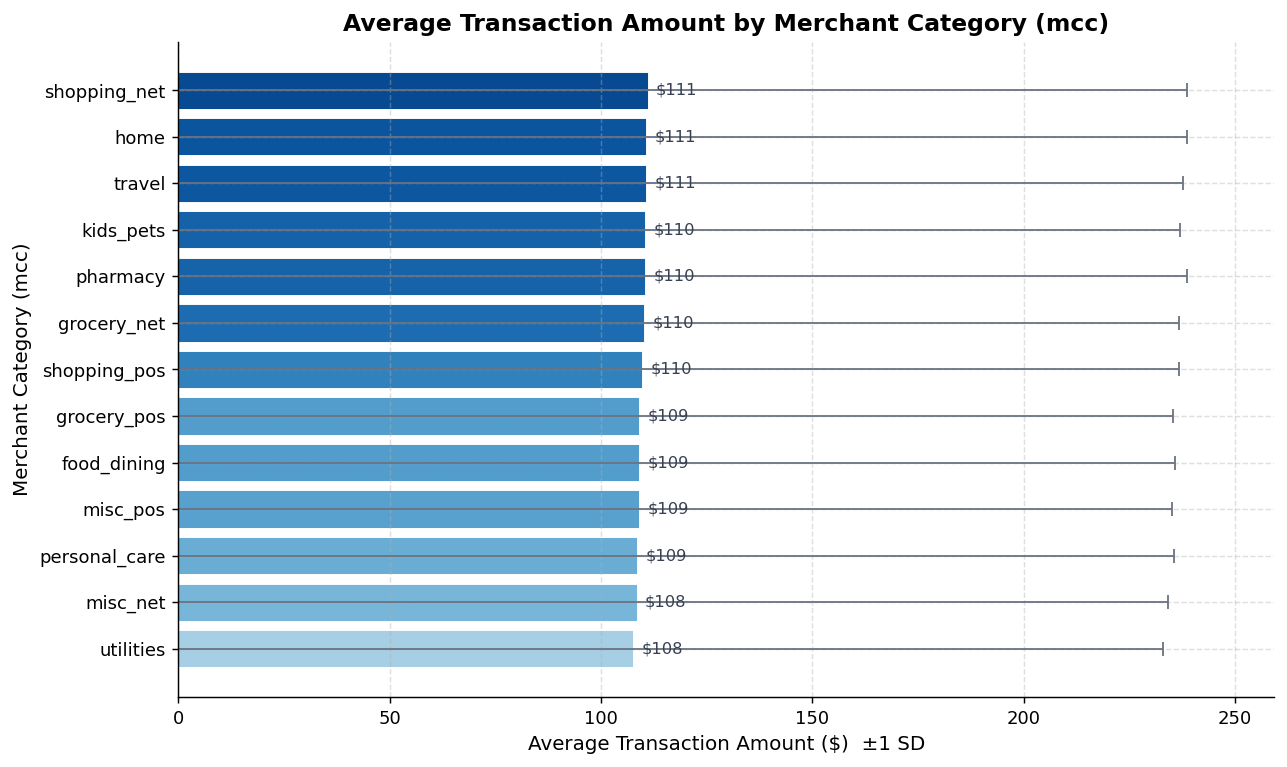

In [6]:
# ── Chart 4: mcc → Horizontal Bar Chart (avg amt per merchant category) ───────

mcc_stats = (
    df.groupby('category')['amt']
    .agg(mean_amt='mean', std_amt='std', count='count')
    .sort_values('mean_amt', ascending=True)
    .reset_index()
)

# Colour bars by average amount (gradient)
norm_vals = (
    (mcc_stats['mean_amt'] - mcc_stats['mean_amt'].min()) /
    (mcc_stats['mean_amt'].max() - mcc_stats['mean_amt'].min())
)
colors = plt.cm.Blues(0.35 + norm_vals * 0.55)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    mcc_stats['category'],
    mcc_stats['mean_amt'],
    xerr=mcc_stats['std_amt'],
    color=colors,
    edgecolor='white',
    linewidth=0.5,
    error_kw=dict(ecolor='#6B7280', capsize=4, linewidth=1),
)

# Annotate values
for bar, val in zip(bars, mcc_stats['mean_amt']):
    ax.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height() / 2,
        f'${val:.0f}',
        va='center',
        fontsize=9,
        color='#374151',
    )

ax.set_xlabel('Average Transaction Amount ($)  ±1 SD', fontsize=11)
ax.set_ylabel('Merchant Category (mcc)', fontsize=11)
ax.set_title('Average Transaction Amount by Merchant Category (mcc)', fontsize=13, fontweight='bold')
ax.set_xlim(0, mcc_stats['mean_amt'].max() + mcc_stats['std_amt'].max() + 20)

plt.tight_layout()
plt.show()

---
## Chart 5 — `lat` / `long`: Geographic Scatter Plot of Cardholders (Hex-Bin Density)

**Why this chart?**  
`lat` and `long` are the cardholder's home coordinates. A **hex-bin scatter plot** maps each unique home location in 2-D geographic space, using color to indicate density. This reveals where customers are concentrated across the continental US — spatial variance that underpins the geo-distance fraud signal (distance from home to merchant).

**Axis rationale:**
- **x-axis** = `long` (longitude): west–east dimension  
- **y-axis** = `lat` (latitude): south–north dimension  
- **Color** = count of unique cardholder homes per hex cell: reveals density clusters

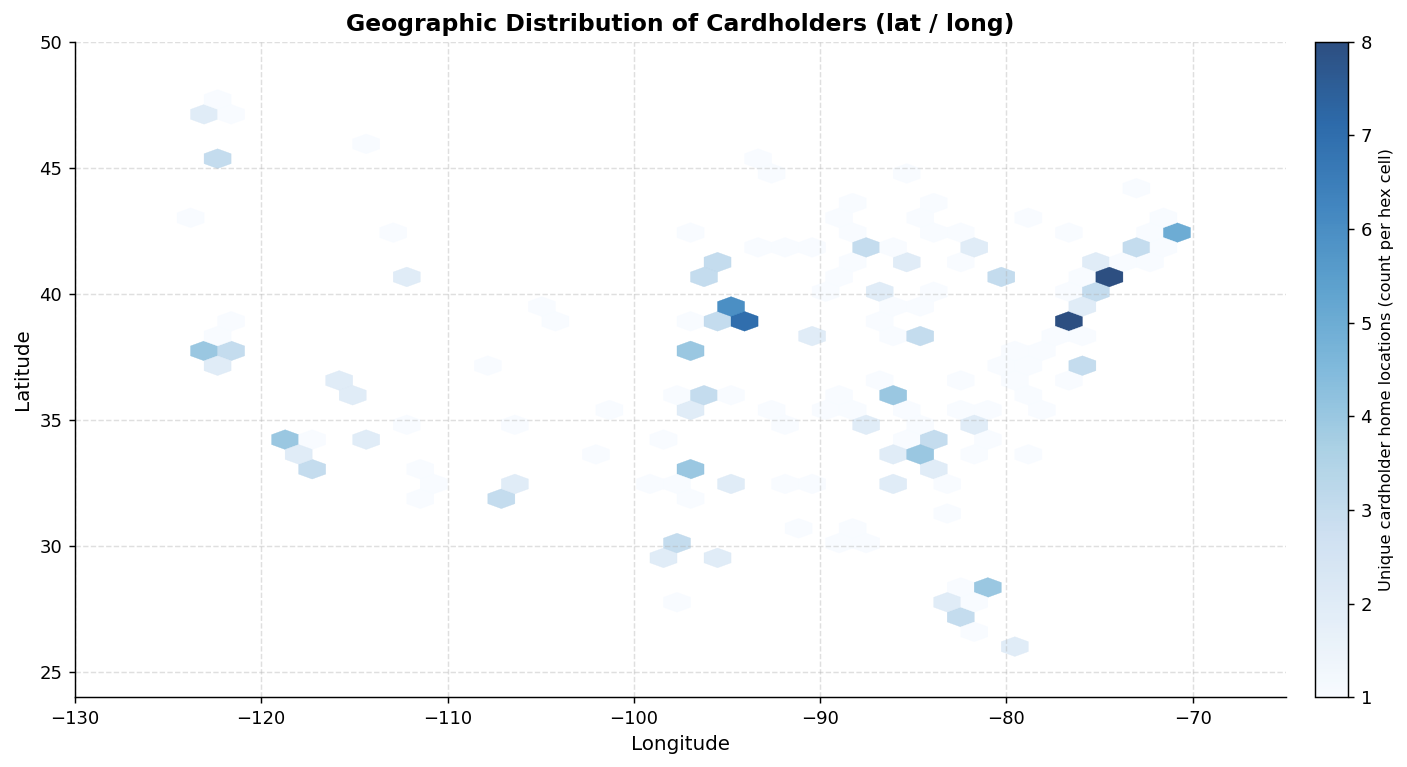

In [7]:
# ── Chart 5: lat / long → Hex-Bin Geographic Scatter ──────────────────────────

# Deduplicate to unique cardholder home locations
geo = df[['lat', 'long']].drop_duplicates()

fig, ax = plt.subplots(figsize=(12, 6))

# Hex-bin density layer
hb = ax.hexbin(
    geo['long'],
    geo['lat'],
    gridsize=60,
    cmap='Blues',
    mincnt=1,
    alpha=0.85,
    linewidths=0.2,
)

cb = fig.colorbar(hb, ax=ax, pad=0.02)
cb.set_label('Unique cardholder home locations (count per hex cell)', fontsize=9)

# Continental US bounding box
ax.set_xlim(-130, -65)
ax.set_ylim(24, 50)

ax.set_xlabel('Longitude', fontsize=11)
ax.set_ylabel('Latitude', fontsize=11)
ax.set_title('Geographic Distribution of Cardholders (lat / long)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

---
## Summary

| # | Attribute | Chart Type | x-axis | y-axis / Color |
|---|-----------|-----------|--------|----------------|
| 1 | `unix_time` | Time-series line + fill + 7-day rolling avg | Date (derived from epoch) | Transactions per day |
| 2 | `transaction_velocity` | Bar chart (fraud zone highlighted) | Velocity value (0–16) | Transaction count |
| 3 | `amt` | Histogram + KDE + median/mean lines | Amount (\$) | Density |
| 4 | `mcc` | Horizontal bar ± 1 SD (gradient color) | Avg amount (\$) | Merchant category |
| 5 | `lat` / `long` | Hex-bin density scatter | Longitude | Latitude |


---
# Attributes 6–8 (Rows 7–9 of `data_visualization_instructions.xlsx`)

| # | Attribute | Data Type | Description |
|---|-----------|-----------|-------------|
| 6 | `merch_lat` / `merch_long` | Decimal | Merchant coordinates |
| 7 | `is_fraud` | Boolean | Ground-truth fraud label (imbalanced) |
| 8 | `cc_num` | String (tokenized) | Tokenized card number |

In [9]:
# ── 2. Load additional columns for Charts 6–8 ────────────────────────────────
# Re-load with the extra columns needed for the next three charts.
df2 = pd.read_csv(
    DATA_PATH,
    sep='|',
    nrows=SAMPLE_N,
    usecols=['lat', 'long', 'merch_lat', 'merch_long', 'is_fraud', 'cc_num'],
)
print(f'Loaded {len(df2):,} rows with columns: {df2.columns.tolist()}')
df2.head()

Loaded 200,000 rows with columns: ['cc_num', 'lat', 'long', 'is_fraud', 'merch_lat', 'merch_long']


,cc_num,lat,long,is_fraud,merch_lat,merch_long
0,5332871012269166,37.1989,-76.5821,0,37.554566,-77.158093
1,5332871012269166,37.1989,-76.5821,0,37.686739,-77.097054
2,5332871012269166,37.1989,-76.5821,0,36.747615,-75.979476
3,5332871012269166,37.1989,-76.5821,0,36.687107,-76.373284
4,5332871012269166,37.1989,-76.5821,0,36.810673,-77.031967


---
## Chart 6 — `merch_lat` / `merch_long`: Customer vs. Merchant Location (Side-by-Side Hex-Bin Map)

**Why this chart?**  
`merch_lat` and `merch_long` encode *where merchants are located*, as opposed to `lat`/`long` which encode where *cardholders live*. Plotting both on the same canvas (side-by-side hex-bin maps) lets us compare the two geographic distributions directly — a critical sanity check for fraud models that rely on the home-to-merchant distance signal.

**Axis rationale:**
- **x-axis** = longitude (west–east) for both subplots  
- **y-axis** = latitude (south–north) for both subplots  
- **Color** = point density per hex cell — shows where each population concentrates

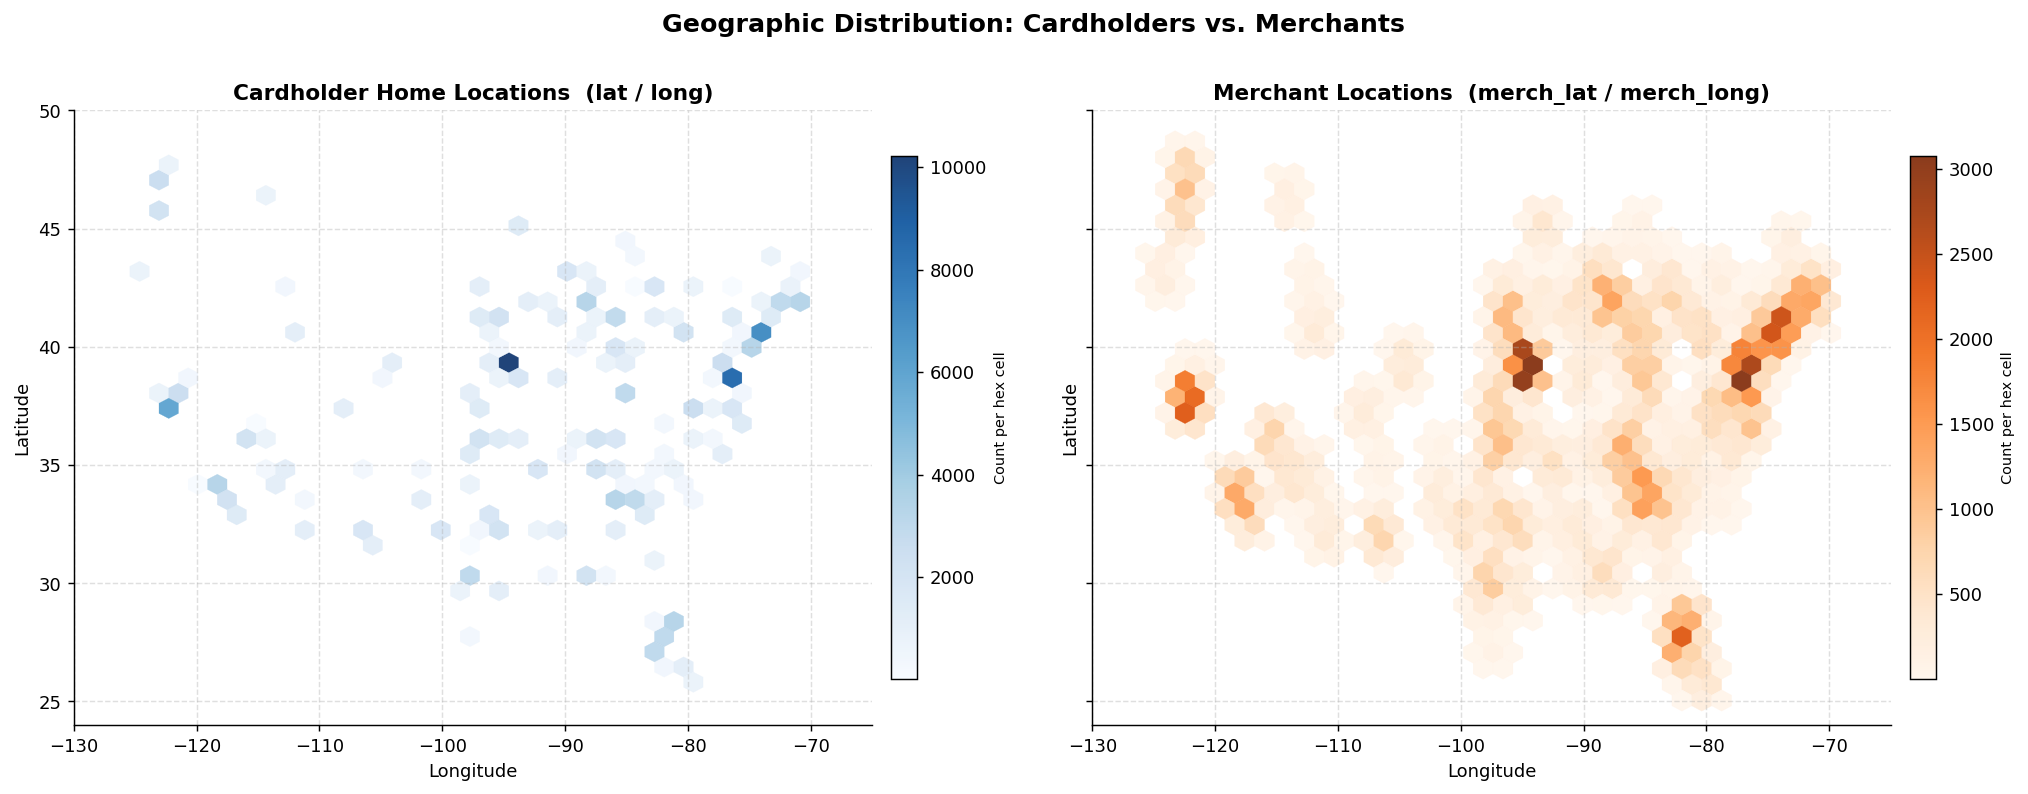

In [10]:
# ── Chart 6: merch_lat / merch_long → Side-by-Side Hex-Bin Maps ──────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

US_LON = (-130, -65)
US_LAT = (24, 50)
GRIDSIZE = 55

panels = [
    (axes[0], df2['long'],       df2['lat'],       'Blues',   'Cardholder Home Locations  (lat / long)'),
    (axes[1], df2['merch_long'], df2['merch_lat'], 'Oranges', 'Merchant Locations  (merch_lat / merch_long)'),
]

for ax, x, y, cmap, title in panels:
    hb = ax.hexbin(
        x, y,
        gridsize=GRIDSIZE,
        cmap=cmap,
        mincnt=1,
        alpha=0.9,
        linewidths=0.15,
    )
    cb = fig.colorbar(hb, ax=ax, pad=0.02, shrink=0.85)
    cb.set_label('Count per hex cell', fontsize=8)
    ax.set_xlim(*US_LON)
    ax.set_ylim(*US_LAT)
    ax.set_xlabel('Longitude', fontsize=10)
    ax.set_ylabel('Latitude', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold')

fig.suptitle(
    'Geographic Distribution: Cardholders vs. Merchants',
    fontsize=14, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.show()

---
## Chart 7 — `is_fraud`: Class Imbalance Bar Chart

**Why this chart?**  
`is_fraud` is a binary label with severe class imbalance — only ~0.85% of transactions are fraudulent. A **vertical bar chart with precise count and percentage annotations** makes the scale of the imbalance unmistakable. This is the foundational diagnostic for any downstream modelling decision (oversampling, class weights, threshold tuning, etc.).

**Axis rationale:**
- **x-axis** = class label (0 = Legitimate, 1 = Fraud): the two classes  
- **y-axis** = transaction count: the raw magnitude of the imbalance  
- A **log-scale inset** is added so the fraud bar is still readable against the dominant legitimate bar

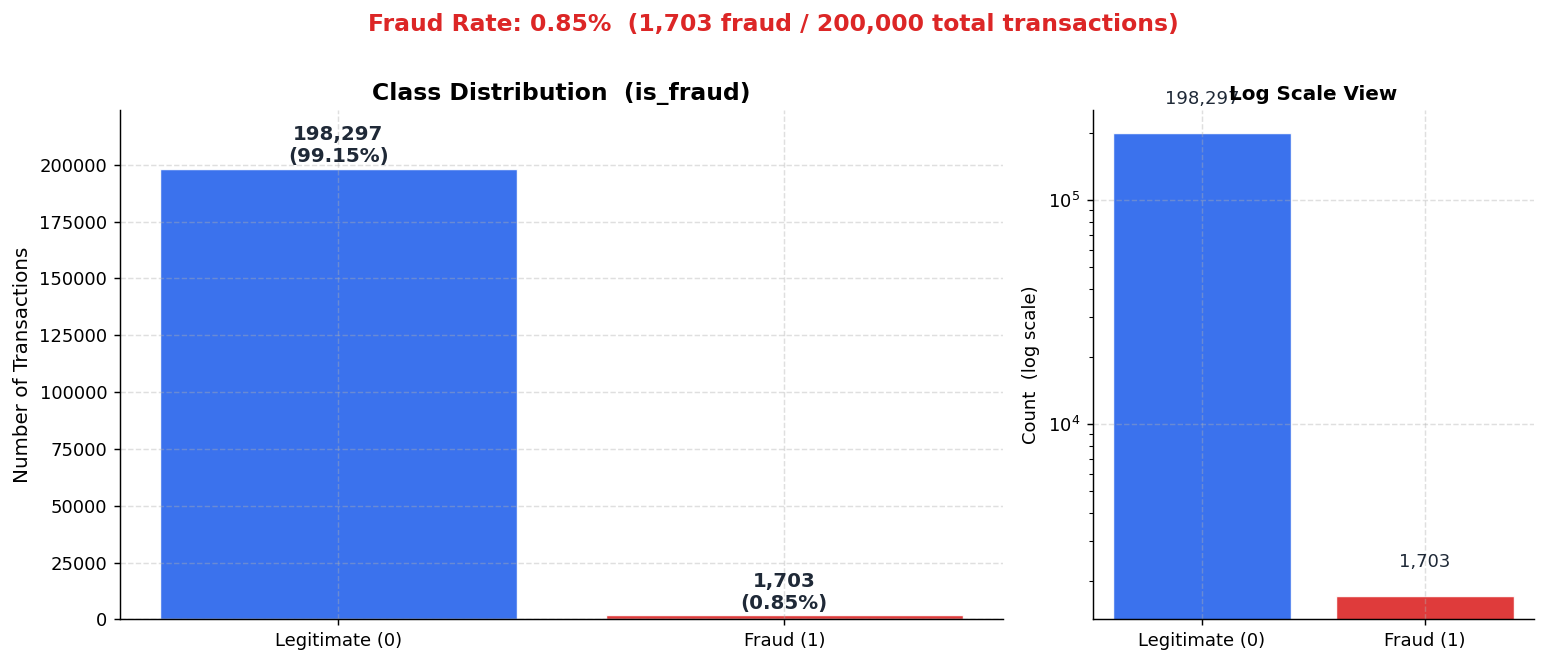

In [11]:
# ── Chart 7: is_fraud → Class Imbalance Bar Chart ────────────────────────────

fraud_counts = df2['is_fraud'].value_counts().sort_index()
labels       = ['Legitimate (0)', 'Fraud (1)']
counts       = fraud_counts.values
total        = counts.sum()
pcts         = counts / total * 100
bar_colors   = ['#2563EB', '#DC2626']

fig, (ax_main, ax_log) = plt.subplots(1, 2, figsize=(12, 5),
                                       gridspec_kw={'width_ratios': [2, 1]})

# ── Main bar (linear scale) ──
bars = ax_main.bar(labels, counts, color=bar_colors, edgecolor='white', linewidth=0.8, alpha=0.9)

for bar, count, pct in zip(bars, counts, pcts):
    ax_main.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + total * 0.005,
        f'{count:,}\n({pct:.2f}%)',
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='#1F2937',
    )

ax_main.set_ylabel('Number of Transactions', fontsize=11)
ax_main.set_title('Class Distribution  (is_fraud)', fontsize=13, fontweight='bold')
ax_main.set_ylim(0, total * 1.12)

# ── Log-scale inset (right panel) so fraud bar is visible ──
bars_log = ax_log.bar(labels, counts, color=bar_colors, edgecolor='white', linewidth=0.8, alpha=0.9)
ax_log.set_yscale('log')
ax_log.set_ylabel('Count  (log scale)', fontsize=10)
ax_log.set_title('Log Scale View', fontsize=11, fontweight='bold')

for bar, count in zip(bars_log, counts):
    ax_log.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() * 1.3,
        f'{count:,}',
        ha='center', va='bottom', fontsize=10, color='#1F2937',
    )

fraud_rate = pcts[1]
fig.suptitle(
    f'Fraud Rate: {fraud_rate:.2f}%  ({counts[1]:,} fraud / {total:,} total transactions)',
    fontsize=13, fontweight='bold', color=ACCENT, y=1.01
)
plt.tight_layout()
plt.show()

---
## Chart 8 — `cc_num`: Transaction Count per Card (Histogram)

**Why this chart?**  
`cc_num` is a tokenized card identifier with **308 unique cards** in the sample. The card number itself carries no ordinal meaning. What varies meaningfully is **how many transactions each card generates** — a proxy for card activity level. A **histogram** of transactions-per-card (x = tx count, y = number of cards in that bin) reveals whether activity is evenly distributed or dominated by a few high-volume cards.

**Axis rationale:**
- **x-axis** = transactions per card (the activity level): the quantity whose variance we measure  
- **y-axis** = number of cards falling in each bin: the frequency distribution  
- A **rug plot** on the x-axis marks each card's exact position; a **KDE overlay** shows the smoothed density

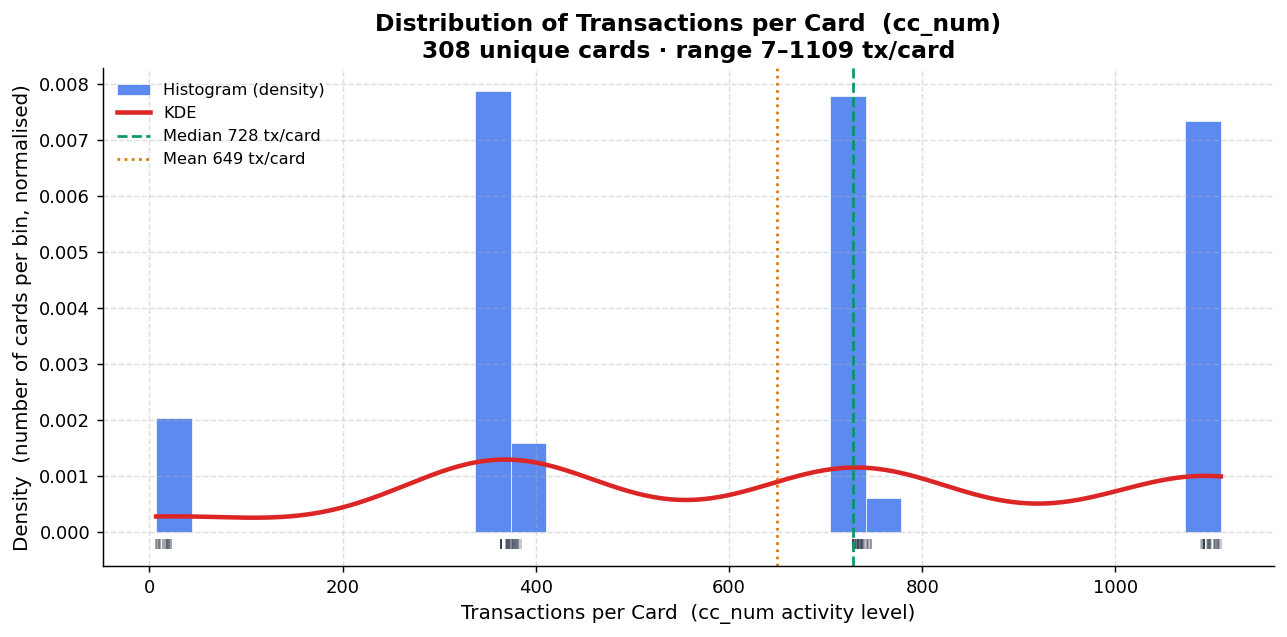

In [12]:
# ── Chart 8: cc_num → Histogram of Transactions per Card ─────────────────────

tx_per_card = df2['cc_num'].value_counts().values  # array of counts, one per unique card

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    tx_per_card,
    bins=30,
    color=PALETTE,
    edgecolor='white',
    linewidth=0.5,
    alpha=0.75,
    density=True,
    label='Histogram (density)',
)

# KDE overlay
kde_card = gaussian_kde(tx_per_card, bw_method='scott')
x_card   = np.linspace(tx_per_card.min(), tx_per_card.max(), 400)
ax.plot(x_card, kde_card(x_card), color=ACCENT, linewidth=2.5, label='KDE')

# Rug plot: one tick per card
ax.plot(tx_per_card, np.full_like(tx_per_card, -0.0002, dtype=float),
        '|', color='#374151', alpha=0.3, markersize=6)

# Annotate summary stats
med_c  = np.median(tx_per_card)
mean_c = np.mean(tx_per_card)
ax.axvline(med_c,  color='#059669', linestyle='--', linewidth=1.5, label=f'Median {med_c:.0f} tx/card')
ax.axvline(mean_c, color='#D97706', linestyle=':',  linewidth=1.5, label=f'Mean {mean_c:.0f} tx/card')

ax.set_xlabel('Transactions per Card  (cc_num activity level)', fontsize=11)
ax.set_ylabel('Density  (number of cards per bin, normalised)', fontsize=11)
ax.set_title(
    f'Distribution of Transactions per Card  (cc_num)\n'
    f'{len(tx_per_card)} unique cards · range {tx_per_card.min()}–{tx_per_card.max()} tx/card',
    fontsize=13, fontweight='bold'
)
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

---
## Summary — Attributes 6–8

| # | Attribute | Chart Type | x-axis | y-axis / Color |
|---|-----------|-----------|--------|----------------|
| 6 | `merch_lat` / `merch_long` | Side-by-side hex-bin maps (vs. cardholder) | Longitude | Latitude / density |
| 7 | `is_fraud` | Dual bar chart: linear + log scale | Class (0 / 1) | Transaction count |
| 8 | `cc_num` | Histogram + KDE + rug plot | Transactions per card | Density (# of cards) |